# Анализ посещаемости интернет-магазина электроники

Синтетическая выгрузка в формате Яндекс.Метрики за ноябрь 2025 — апрель 2026.
Каждая строка сырого файла — сегмент дня: источник, устройство, браузер, операционная система и страна.

Графики ниже читают уже очищенные срезы из `data/processed/`. Почасовая тепловая карта построена по модели суточного профиля: в сырой выгрузке часа нет, дневные сессии разложены по типичному ритму магазина.


## Загрузка и первичный осмотр данных


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.figsize": (12, 6),
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "#f8fafc",
    "axes.titlesize": 16,
    "axes.titleweight": "semibold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "axes.unicode_minus": False,
})

SOURCE_COLORS = {
    "Органический поиск": "#2563eb",
    "Платная реклама": "#f59e0b",
    "Прямые заходы": "#0f766e",
    "Социальные сети": "#8b5cf6",
    "Переходы с сайтов": "#64748b",
}
DEVICE_COLORS = {
    "Смартфон": "#2563eb",
    "Десктоп": "#0f766e",
    "Планшет": "#f59e0b",
}
DEVICE_ORDER = ["Смартфон", "Десктоп", "Планшет"]
WEEKDAY_ORDER = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]


def fmt_int(value: float) -> str:
    """Форматирует целое с пробелом между разрядами."""
    return f"{int(round(value)):,}".replace(",", " ")


def axis_thousands(value: float, _position: int) -> str:
    """Подпись оси без дробной части."""
    return fmt_int(value)


def find_root() -> Path:
    """Ищет корень проекта и от текущей папки, и от папки ноутбука."""
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "yandex_metrics_raw.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Не найден data/raw/yandex_metrics_raw.csv. "
        "Запустите scripts/generate_data.py из корня проекта."
    )


def read_table(path: Path) -> pd.DataFrame:
    """Читает CSV и объясняет, почему файл не открылся."""
    if not path.exists():
        raise FileNotFoundError(
            f"Файл не найден: {path}. Сначала выполните scripts/process_data.py."
        )
    if path.stat().st_size == 0:
        raise ValueError(f"Файл пустой: {path}")
    try:
        return pd.read_csv(path, encoding="utf-8-sig")
    except pd.errors.EmptyDataError as exc:
        raise ValueError(f"В файле нет таблицы: {path}") from exc
    except pd.errors.ParserError as exc:
        raise ValueError(f"CSV не разбирается: {path}") from exc
    except OSError as exc:
        raise OSError(f"Ошибка чтения файла: {path}") from exc


ROOT = find_root()
PROCESSED = ROOT / "data" / "processed"
raw = read_table(ROOT / "data" / "raw" / "yandex_metrics_raw.csv")
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
monthly = read_table(PROCESSED / "monthly_metrics.csv")
hourly = read_table(PROCESSED / "hourly_activity.csv")
flat = read_table(PROCESSED / "powerbi_ready.csv")
flat["date"] = pd.to_datetime(flat["date"], errors="coerce")

print(f"Строк в сырой выгрузке: {fmt_int(len(raw))}")
print(f"Период: {raw['date'].min():%d.%m.%Y} — {raw['date'].max():%d.%m.%Y}")
print(f"Пустых ячеек: {fmt_int(raw.isna().sum().sum())}")
print(f"Сессий: {fmt_int(raw['sessions'].sum())}")
display(raw.head(8))


Строк в сырой выгрузке: 53 785
Период: 01.11.2025 — 30.04.2026
Пустых ячеек: 12
Сессий: 1 107 817


,date,sessions,users,pageviews,bounce_rate,avg_session_duration,pages_per_session,traffic_source,device_type,browser,os,country,conversions,revenue
0,2025-11-01,9,7,41,24.93,324.8,4.56,direct,desktop,Chrome,Windows,Беларусь,1,13227.05
1,2025-11-01,7,5,29,25.09,315.1,4.14,direct,desktop,Chrome,Windows,Казахстан,0,0.00
2,2025-11-01,96,71,421,24.32,304.6,4.39,direct,desktop,Chrome,Windows,Россия,3,43872.01
3,2025-11-01,4,3,18,24.63,318.7,4.50,direct,desktop,Chrome,Windows,Украина,1,16172.38
4,2025-11-01,6,4,26,24.81,335.4,4.33,direct,desktop,Chrome,Windows,другие,1,17506.07
5,2025-11-01,1,1,4,25.89,301.3,4.00,direct,desktop,Chrome,macOS,Беларусь,0,0.00
6,2025-11-01,2,1,9,22.71,325.9,4.50,direct,desktop,Chrome,macOS,Казахстан,0,0.00
7,2025-11-01,11,8,48,25.53,320.9,4.36,direct,desktop,Chrome,macOS,Россия,0,0.00


In [2]:
# Сводка числовых полей и доли устройств — проверка, что выгрузка похожа на магазин
summary = raw.describe().T
summary = summary[["count", "mean", "std", "min", "50%", "max"]].round(2)
display(summary)

device_share = raw.groupby("device_type")["sessions"].sum()
device_share = (device_share / device_share.sum() * 100).round(1).sort_values(ascending=False)
print("Доля сессий по устройствам, %:")
print(device_share.to_string())
print(
    "Вывод. Таблица покрывает шесть месяцев и уже содержит сегменты, "
    f"из которых дальше собираются графики. Пустых ячеек: {fmt_int(raw.isna().sum().sum())}. "
    "Их закрывает scripts/process_data.py медианой столбца. "
    "Смартфоны дают основную массу визитов, десктоп — вторую, планшеты — узкий хвост."
)


,count,mean,std,min,50%,max
date,53785,2026-01-29 10:33:25.719066880,NaN,2025-11-01 00:00:00,2026-01-30 00:00:00,2026-04-30 00:00:00
sessions,53785.0,20.597137,53.097685,1.0,5.0,910.0
users,53785.0,17.522822,45.444421,1.0,4.0,832.0
pageviews,53785.0,64.56895,161.472352,2.0,16.0,2514.0
bounce_rate,53779.0,39.771218,12.028168,20.01,38.38,74.59
avg_session_duration,53779.0,218.234043,83.709069,79.4,214.6,401.2
pages_per_session,53785.0,3.270407,0.791495,1.67,3.0,5.4
conversions,53785.0,0.590462,1.744075,0.0,0.0,29.0
revenue,53785.0,7108.55026,21972.819637,0.0,0.0,479307.88


Доля сессий по устройствам, %:
device_type
mobile     59.7
desktop    35.3
tablet      5.0
Вывод. Таблица покрывает шесть месяцев и уже содержит сегменты, из которых дальше собираются графики. Пустых ячеек: 12. Их закрывает scripts/process_data.py медианой столбца. Смартфоны дают основную массу визитов, десктоп — вторую, планшеты — узкий хвост.


## Динамика посещаемости по месяцам


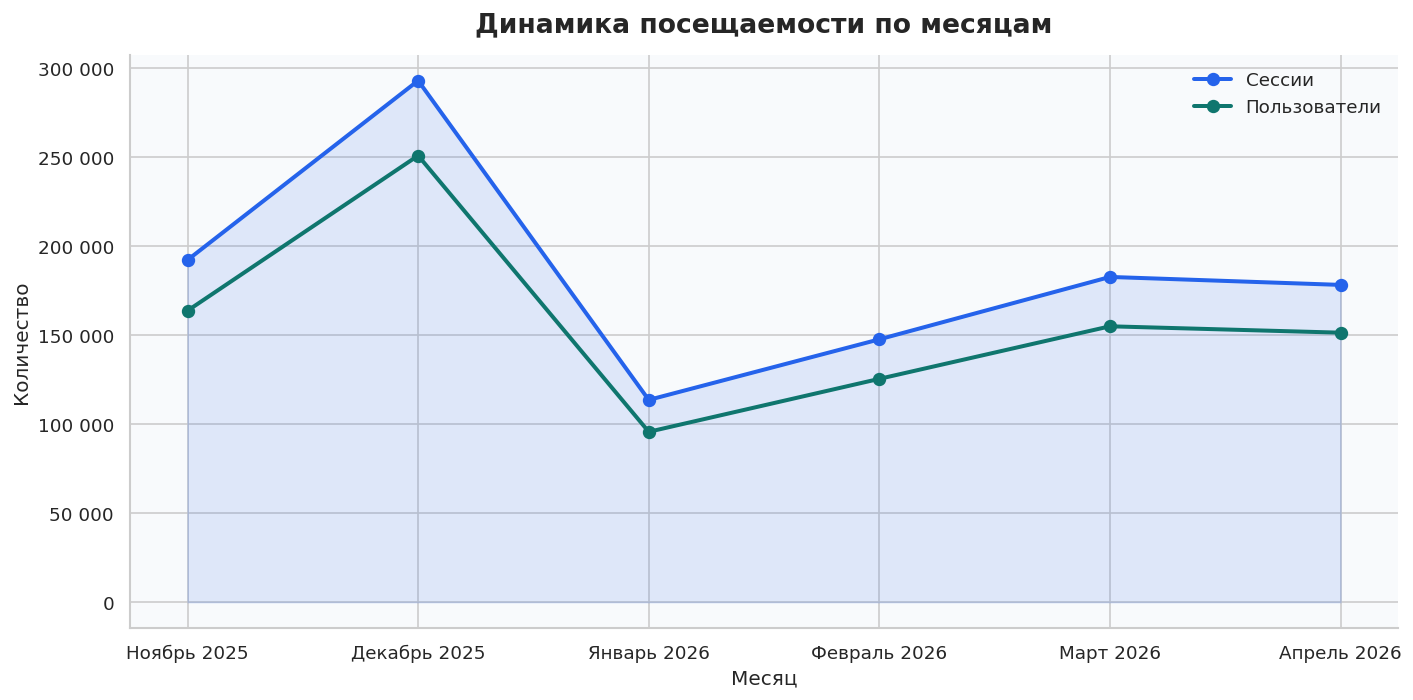

Вывод. Максимум сессий — Декабрь 2025 (293 094), минимум — Январь 2026 (113 665). Пиковый месяц выше минимума на 158%. Подъём совпадает с новогодними покупками, спад — с каникулами первой недели января.


In [3]:
fig, ax = plt.subplots()
x = np.arange(len(monthly))
ax.plot(x, monthly["sessions"], color="#2563eb", marker="o", linewidth=2.4, markersize=7, label="Сессии")
ax.plot(x, monthly["users"], color="#0f766e", marker="o", linewidth=2.4, markersize=7, label="Пользователи")
ax.fill_between(x, monthly["sessions"], color="#2563eb", alpha=0.12)
ax.set_xticks(x)
ax.set_xticklabels(monthly["month_label"])
ax.yaxis.set_major_formatter(FuncFormatter(axis_thousands))
ax.set_title("Динамика посещаемости по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество")
ax.legend()
fig.tight_layout()
plt.show()

peak = monthly.loc[monthly["sessions"].idxmax()]
low = monthly.loc[monthly["sessions"].idxmin()]
gap = (peak["sessions"] / low["sessions"] - 1) * 100
text = (
    f"Вывод. Максимум сессий — {peak['month_label']} ({fmt_int(peak['sessions'])}), "
    f"минимум — {low['month_label']} ({fmt_int(low['sessions'])}). "
    f"Пиковый месяц выше минимума на {gap:.0f}%."
)
if "Декабрь" in str(peak["month_label"]) and "Январь" in str(low["month_label"]):
    text += " Подъём совпадает с новогодними покупками, спад — с каникулами первой недели января."
else:
    text += " Пик и спад стоит сверить с промокалендарём: 11.11, чёрная пятница, 23 февраля и 8 марта."
print(text)


## Распределение трафика по источникам


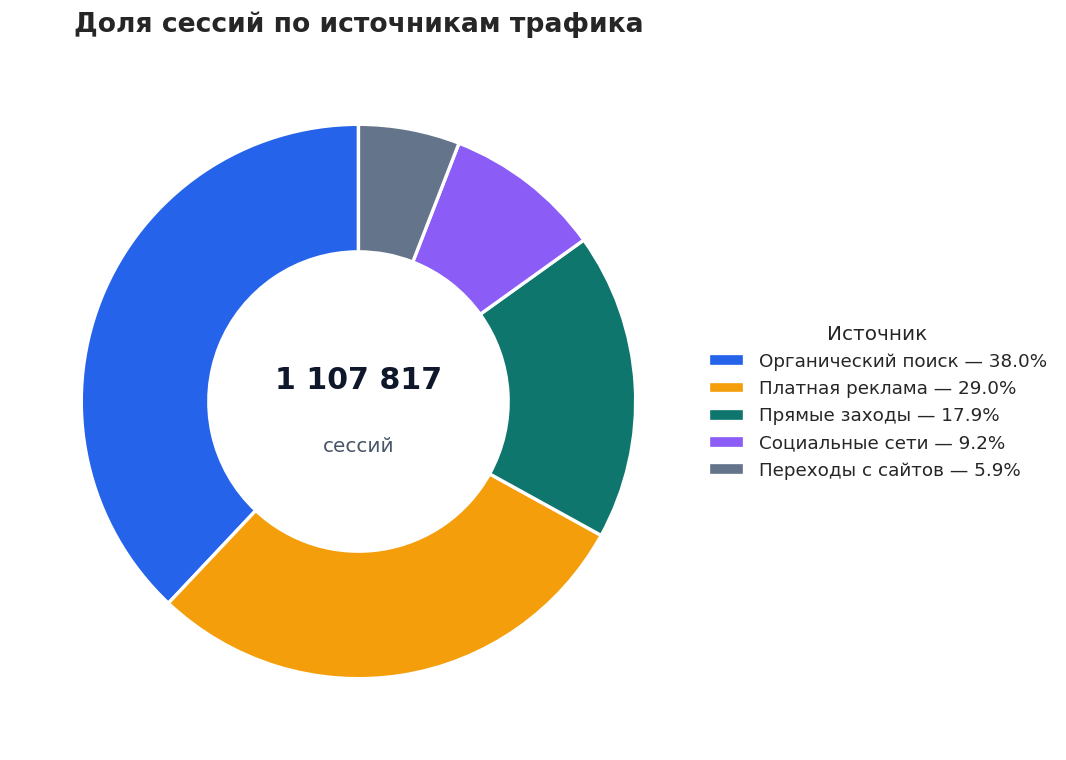

Вывод. Крупнейший источник — Органический поиск (38.0% сессий). Вместе с источником «Платная реклама» это 67% трафика. Поиск и платная реклама приводят основную аудиторию, социальные сети и переходы с других сайтов остаются дополнением.


In [4]:
sources = (
    flat.groupby("traffic_source_ru", as_index=False)["sessions"]
    .sum()
    .sort_values("sessions", ascending=False)
)
shares = sources["sessions"] / sources["sessions"].sum() * 100
colors = [SOURCE_COLORS.get(name, "#94a3b8") for name in sources["traffic_source_ru"]]
legend = [f"{name} — {share:.1f}%" for name, share in zip(sources["traffic_source_ru"], shares)]

fig, ax = plt.subplots(figsize=(10, 6.5))
wedges, _ = ax.pie(
    sources["sessions"],
    colors=colors,
    startangle=90,
    wedgeprops={"width": 0.46, "edgecolor": "white", "linewidth": 2},
)
ax.legend(wedges, legend, loc="center left", bbox_to_anchor=(0.98, 0.5), title="Источник")
ax.text(0, 0.08, fmt_int(sources["sessions"].sum()), ha="center", va="center", fontsize=18, fontweight="semibold", color="#0f172a")
ax.text(0, -0.16, "сессий", ha="center", va="center", fontsize=12, color="#475569")
ax.set_title("Доля сессий по источникам трафика")
fig.tight_layout()
plt.show()

top = sources.iloc[0]
second = sources.iloc[1]
top_share = shares.iloc[0] + shares.iloc[1]
print(
    f"Вывод. Крупнейший источник — {top['traffic_source_ru']} ({shares.iloc[0]:.1f}% сессий). "
    f"Вместе с источником «{second['traffic_source_ru']}» это {top_share:.0f}% трафика. "
    "Поиск и платная реклама приводят основную аудиторию, социальные сети и переходы с других сайтов остаются дополнением."
)


## Сравнение конверсии по устройствам


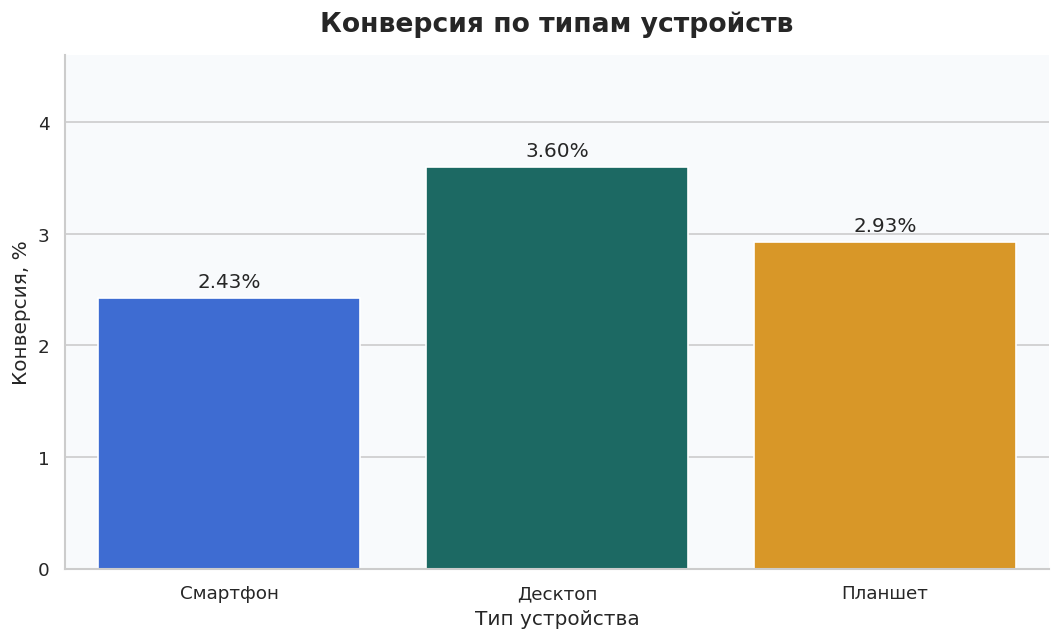

Вывод. Выше всего конверсия на устройстве «Десктоп» — 3.60%. Смартфоны приносят 60% сессий при конверсии 2.43%. Дорогую электронику чаще доводят до заказа с компьютера, хотя заходят в магазин в основном с телефона.


In [5]:
devices = flat.groupby("device_type_ru", as_index=False).agg(
    sessions=("sessions", "sum"),
    conversions=("conversions", "sum"),
)
devices["conversion_rate"] = devices["conversions"] / devices["sessions"] * 100
devices["traffic_share"] = devices["sessions"] / devices["sessions"].sum() * 100
devices["device_type_ru"] = pd.Categorical(devices["device_type_ru"], DEVICE_ORDER, ordered=True)
devices = devices.sort_values("device_type_ru")

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(
    data=devices,
    x="device_type_ru",
    y="conversion_rate",
    hue="device_type_ru",
    palette=DEVICE_COLORS,
    legend=False,
    ax=ax,
    order=DEVICE_ORDER,
)
for index, row in devices.reset_index(drop=True).iterrows():
    ax.text(index, row["conversion_rate"] + 0.06, f"{row['conversion_rate']:.2f}%", ha="center", va="bottom", fontsize=12)
ax.set_ylim(0, devices["conversion_rate"].max() * 1.28)
ax.set_title("Конверсия по типам устройств")
ax.set_xlabel("Тип устройства")
ax.set_ylabel("Конверсия, %")
fig.tight_layout()
plt.show()

best = devices.loc[devices["conversion_rate"].idxmax()]
mobile = devices.loc[devices["device_type_ru"] == "Смартфон"].iloc[0]
print(
    f"Вывод. Выше всего конверсия на устройстве «{best['device_type_ru']}» — {best['conversion_rate']:.2f}%. "
    f"Смартфоны приносят {mobile['traffic_share']:.0f}% сессий при конверсии {mobile['conversion_rate']:.2f}%. "
    "Дорогую электронику чаще доводят до заказа с компьютера, хотя заходят в магазин в основном с телефона."
)


## Корреляция времени сессии и конверсии


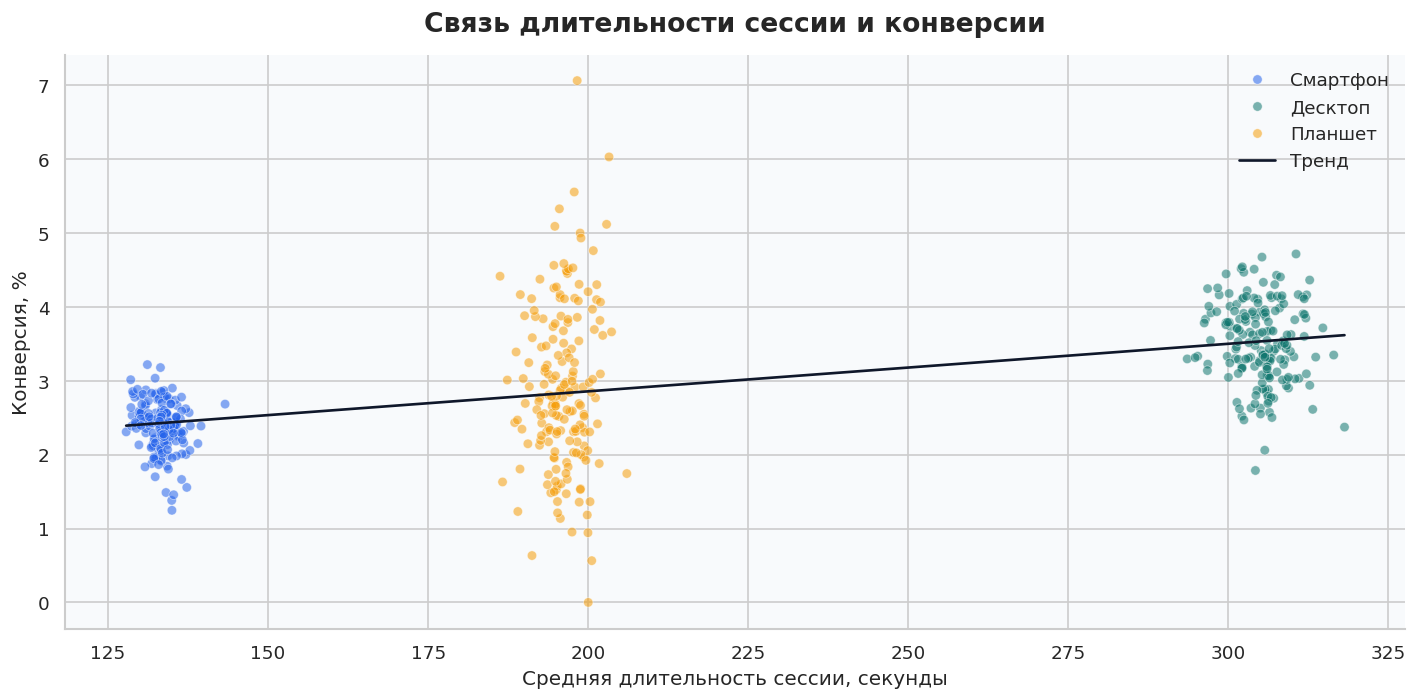

Вывод. Корреляция Пирсона равна 0.53, связь положительная. Точки устройств стоят отдельными облаками: у смартфонов сессии короче и конверсия ниже, у десктопа человек дольше сравнивает карточки и чаще совершает целевое действие.


In [6]:
points = flat.groupby(["date", "device_type_ru"], as_index=False).agg(
    sessions=("sessions", "sum"),
    conversions=("conversions", "sum"),
    total_duration_sec=("total_duration_sec", "sum"),
)
points = points[points["sessions"] > 0].copy()
points["conversion_rate"] = points["conversions"] / points["sessions"] * 100
points["avg_session_duration"] = points["total_duration_sec"] / points["sessions"]
points["device_type_ru"] = pd.Categorical(points["device_type_ru"], DEVICE_ORDER, ordered=True)

fig, ax = plt.subplots()
sns.scatterplot(
    data=points,
    x="avg_session_duration",
    y="conversion_rate",
    hue="device_type_ru",
    hue_order=DEVICE_ORDER,
    palette=DEVICE_COLORS,
    alpha=0.55,
    s=32,
    ax=ax,
)
slope, intercept = np.polyfit(points["avg_session_duration"], points["conversion_rate"], 1)
xs = np.linspace(points["avg_session_duration"].min(), points["avg_session_duration"].max(), 120)
ax.plot(xs, slope * xs + intercept, color="#0f172a", linewidth=1.6, label="Тренд")
ax.set_title("Связь длительности сессии и конверсии")
ax.set_xlabel("Средняя длительность сессии, секунды")
ax.set_ylabel("Конверсия, %")
ax.legend(title="")
fig.tight_layout()
plt.show()

correlation = points["avg_session_duration"].corr(points["conversion_rate"])
direction = "положительная" if correlation >= 0 else "отрицательная"
print(
    f"Вывод. Корреляция Пирсона равна {correlation:.2f}, связь {direction}. "
    "Точки устройств стоят отдельными облаками: у смартфонов сессии короче и конверсия ниже, "
    "у десктопа человек дольше сравнивает карточки и чаще совершает целевое действие."
)


## Тепловая карта активности по дням недели и часам

Час восстановлен из дневного числа сессий по типовому профилю магазина. Цвет показывает среднее число сессий в этот час данного дня недели.


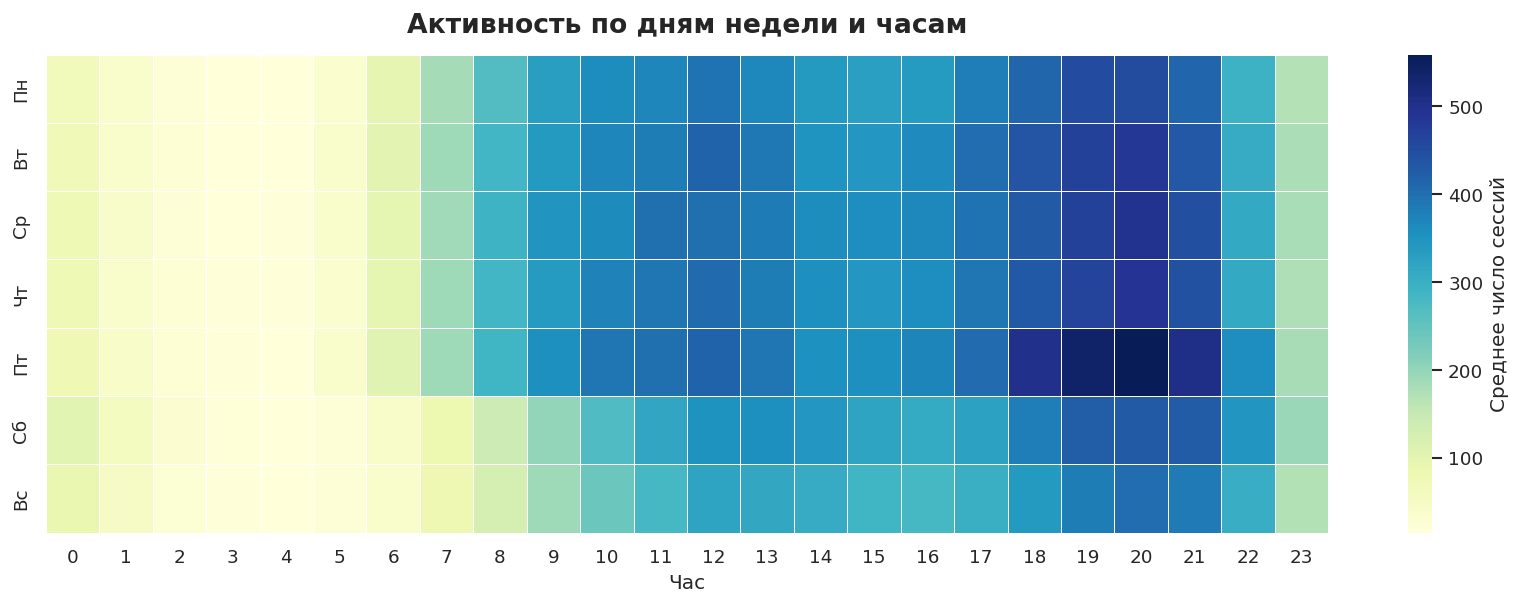

Вывод. Самый плотный час — Пт, 20:00 (559 сессий в среднем). Самый тихий — Пн, 4:00. В будни заметен дневной и вечерний подъём, ночью визитов мало. В субботу и воскресенье активность сдвигается на более позднее время.


In [7]:
heat = hourly.pivot_table(index="weekday", columns="hour", values="sessions", aggfunc="mean")
heat = heat.reindex(index=WEEKDAY_ORDER, columns=list(range(24))).fillna(0)

fig, ax = plt.subplots(figsize=(14, 5.2))
sns.heatmap(
    heat,
    cmap="YlGnBu",
    ax=ax,
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Среднее число сессий"},
)
ax.set_title("Активность по дням недели и часам")
ax.set_xlabel("Час")
ax.set_ylabel("")
ax.set_xticklabels([str(hour) for hour in heat.columns], rotation=0)
fig.tight_layout()
plt.show()

weekday, hour = heat.stack().idxmax()
quiet_day, quiet_hour = heat.stack().idxmin()
print(
    f"Вывод. Самый плотный час — {weekday}, {int(hour)}:00 "
    f"({heat.loc[weekday, hour]:.0f} сессий в среднем). "
    f"Самый тихий — {quiet_day}, {int(quiet_hour)}:00. "
    "В будни заметен дневной и вечерний подъём, ночью визитов мало. "
    "В субботу и воскресенье активность сдвигается на более позднее время."
)


## Итоговые выводы

- Посещаемость следует календарю спроса: конец ноября и декабрь поднимают сессии, первая неделя января их просаживает, отдельные всплески дают 14 февраля, 23 февраля и 8 марта.
- Опора трафика — органический поиск и платная реклама. Прямые заходы конвертируют лучше остальных: это люди, которые уже знают магазин.
- Смартфоны приносят большую часть визитов. Конверсия выше на десктопе, поэтому мобильную карточку товара и корзину имеет смысл разбирать отдельно от настольной версии.
- Длинная сессия и покупка идут вместе. Короткие визиты с телефона чаще обрываются до целевого действия.
- Рекламу и рассылки выгоднее ставить на будний день и вечер. Ночной слот для этого ассортимента почти пустой.
